# Notebook #2a: ALA Exploratory Data Analysis

## 1.0 Project Dependencies

### 1.1 Pip Installs

In [1]:
# !pip install wordcloud

### 1.2 Import Libraries

In [2]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as py
import plotly.graph_objs as go
import plotly.express as px
from plotly.subplots import make_subplots
import matplotlib.ticker as mticker
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

### 1.3 Standardize Setup & Styling

In [3]:
ALA_BLUE   = '#003F72'
ALA_RED    = '#C8102E'
ACRL_TEAL  = '#00857C'
ACCENT     = '#F5A623'
LIGHT_GRAY = '#F4F4F4'

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   LIGHT_GRAY,
    'axes.spines.top':  False,
    'axes.spines.right':False,
    'font.family':      'sans-serif',
    'axes.titlesize':   13,
    'axes.labelsize':   11,
})

<hr>

## 2.0 Import Cleaned Datasets

### 2.1 Load ACRL Datasets

In [4]:
acrl_google       = pd.read_parquet("Cleaned Datasets/acrl_google")
acrl_indiv_emails = pd.read_parquet("Cleaned Datasets/acrl_indiv_emails")
acrl_syllabus     = pd.read_parquet("Cleaned Datasets/acrl_syllabus")
acrl_all_emails   = pd.read_parquet("Cleaned Datasets/acrl_all_emails")

In [5]:
# acrl_datasets = [acrl_google, acrl_indiv_emails, acrl_syllabus]

# for df in acrl_datasets: 
#     print(df.head(3).to_markdown())
#     print(df.dtypes)
#     print(df.shape)

### 2.2 Load ALA Editions Datsets

In [6]:
# ALA Editions
editions_eblasts     = pd.read_parquet("Cleaned Datasets/editions_ala_eblasts.parquet")
editions_fw26_google = pd.read_parquet("Cleaned Datasets/editions_ala_fw26_google.parquet")
editions_ss25_google = pd.read_parquet("Cleaned Datasets/editions_ala_ss25_google.parquet")
editions_ala_stats   = pd.read_parquet("Cleaned Datasets/editions_ala_stats_eblasts")

In [7]:
# ala_datasets = [editions_eblasts, editions_fw26_google, editions_ss25_google, editions_ala_stats]

# for df in ala_datasets: 
#     print(df.head(3).to_markdown())
#     print(df.dtypes)
#     print(df.shape)

### 2.3 Isolate Homepage Rows for Time-Series Work

In [8]:
ss25_home = editions_ss25_google[editions_ss25_google['page_path_and_screen_class'] == '/SS25catalog'].copy()
fw26_home = editions_fw26_google[editions_fw26_google['page_path_and_screen_class'] == '/FW26catalog'].copy()

# Remove Cummulative Values (Week 0)
ss25_home = ss25_home[ss25_home['week'] != 0]
fw26_home = fw26_home[fw26_home['week'] != 0]

### 2.4 Summary Statistics (SS25 & FW26)

In [9]:
def catalog_summary(df_home, label):
    """Return key aggregate stats for a catalog homepage time-series."""
    return pd.Series({
        'Catalog': label,
        'Weeks Tracked':          int(df_home['week'].nunique()) -1,
        'Total Views':            df_home['views'].sum(),
        'Total Active Users':     df_home['active_users'].sum(),
        'Avg Views/User':         round(df_home['views_per_active_user'].mean(), 2),
        'Avg Engagement Time (s)':round(df_home['average_engagement_time_per_active_user'].mean(), 1),
        'Total Events':           df_home['event_count'].sum(),
    })

summary_table = pd.DataFrame([
    catalog_summary(ss25_home, 'SS25'),
    catalog_summary(fw26_home, 'FW26'),
]).set_index('Catalog')

display(summary_table)

,Weeks Tracked,Total Views,Total Active Users,Avg Views/User,Avg Engagement Time (s),Total Events
Catalog,,,,,,
SS25,23,5104,4184,1.31,23.7,15847
FW26,18,23311,13291,1.52,19.6,50159


### 2.5 Summary Statistics (eBlast Performance)

In [10]:
stats = editions_ala_stats.copy()

summary = pd.DataFrame({
    'Metric': ['Total E-Blasts', 'Total Delivered', 'Avg Open Rate (%)', 
               'Avg Click Rate (%)', 'Avg Unsubscribe Rate (%)', 
               'Avg Delivery Rate (%)'],
    'Value': [
        len(stats),
        f"{stats['Delivered'].sum():,}",
        round(stats['Opened %'].mean(), 2),
        round(stats['Clicked %'].mean(), 2),
        round(stats['Unsubs %'].mean(), 3),
        round(stats['Delivered %'].mean(), 2),
    ]
})

display(summary.set_index('Metric'))

,Value
Metric,
Total E-Blasts,33
Total Delivered,"2,309,923"
Avg Open Rate (%),21.7
Avg Click Rate (%),7.52
Avg Unsubscribe Rate (%),0.13
Avg Delivery Rate (%),99.09


<hr>

## 3.0 Exploratory Data Analysis

In [11]:
# Comparing the full catalog google analytics week by week for FW26
editions_fw26_google_wbw = editions_fw26_google.loc[editions_fw26_google['page_path_and_screen_class'] == '/FW26catalog']
editions_fw26_google_wbw = editions_fw26_google_wbw[editions_fw26_google_wbw['week'] != 0]
editions_fw26_google_wbw.head()

,page_path_and_screen_class,views,active_users,views_per_active_user,average_engagement_time_per_active_user,event_count,key_events,total_revenue,week,start_date,end_date
20,/FW26catalog,1097,881,1.245176,25.664018,3730,0,0,1,2025-09-14,2025-09-20
37,/FW26catalog,48,30,1.600000,28.566667,117,0,0,2,2025-11-16,2025-11-22
53,/FW26catalog,31,20,1.550000,15.200000,84,0,0,3,2025-11-23,2025-11-29
67,/FW26catalog,913,868,1.051843,5.764977,3146,0,0,4,2025-11-30,2025-12-06
84,/FW26catalog,1354,538,2.516729,19.102230,2801,0,0,5,2025-12-07,2025-12-13


In [12]:
# Comparing the full catalog google analytics week by week for SS25
editions_ss25_google_wbw = editions_ss25_google.loc[editions_ss25_google['page_path_and_screen_class'] == '/SS25catalog']
editions_ss25_google_wbw = editions_ss25_google_wbw[editions_ss25_google_wbw['week'] != 0]
editions_ss25_google_wbw.head()

,page_path_and_screen_class,views,active_users,views_per_active_user,average_engagement_time_per_active_user,event_count,key_events,total_revenue,week,start_date,end_date
20,/SS25catalog,1551,1207,1.285004,27.201326,4751,0,0,1,2025-04-06,2025-04-12
38,/SS25catalog,158,134,1.179104,31.000000,445,0,0,2,2025-06-08,2025-06-14
54,/SS25catalog,182,157,1.159236,19.242038,552,0,0,3,2025-06-15,2025-06-21
69,/SS25catalog,152,125,1.216000,29.536000,446,0,0,4,2025-06-22,2025-06-28
86,/SS25catalog,124,99,1.252525,20.919192,321,0,0,5,2025-06-29,2025-07-05


<hr>

## 4.0 Trends Over Time

### 4.1 Weekly Views Over Time

#### 4.1.1 Editions SS25
**By Deepnote AI**

This section visualizes the SS25 catalog weekly views over time. We sort the data by week, plot interactive markers for each week, and overlay a smoothed trend line to highlight overall behavior. The code will fall back to Matplotlib/Seaborn if Plotly isn't available, and it checks for required columns to handle missing data gracefully.

In [13]:
# SS25 weekly views over time visualization with interactive Plotly and LOWESS trend (fallback to Seaborn)
import warnings
warnings.filterwarnings("ignore")

# Validate DataFrame availability
if 'editions_ss25_google_wbw' not in globals():
    print("The DataFrame 'editions_ss25_google_wbw' is not available in the notebook.")
else:
    df_ss = editions_ss25_google_wbw.copy()
    required_cols = {'week', 'views'}
    missing = [c for c in required_cols if c not in df_ss.columns]
    if missing:
        print(f"Missing required column(s) in 'editions_ss25_google_wbw': {missing}. Please ensure the DataFrame contains 'week' and 'views'.")
    else:
        # Ensure numeric types for plotting
        df_ss['week'] = pd.to_numeric(df_ss['week'], errors='coerce')
        df_ss['views'] = pd.to_numeric(df_ss['views'], errors='coerce')
        
        # Drop rows with NaNs in required columns
        df_ss = df_ss.dropna(subset=['week', 'views'])
        
        # Sort by week ascending
        df_ss = df_ss.sort_values('week', ascending=True)
        
        # Try Plotly Express first for interactivity
        try:
            import plotly.express as px
            # Base line with markers
            fig = px.line(
                df_ss, x='week', y='views', markers=True,
                title='SS25 Catalog — Weekly Views Over Time'
            )
            fig.update_layout(xaxis_title='Week', yaxis_title='Views')
            
            # Add LOWESS smoothed trend (7-day-equivalent smoothing via lowess)
            try:
                from statsmodels.nonparametric.smoothers_lowess import lowess
                # frac approximates smoothing window relative to data length; 7-week equivalent is too coarse.
                # Use a modest fraction to smooth while preserving shape. Adjust based on data length.
                n = len(df_ss)
                # Aim for smoothing window ~ 5 points or ~ 20% of data if small
                frac = max(0.1, min(0.3, 5 / n)) if n > 0 else 0.2
                smoothed = lowess(df_ss['views'], df_ss['week'], frac=frac, return_sorted=True)
                fig.add_scatter(x=smoothed[:, 0], y=smoothed[:, 1], mode='lines', name='LOWESS trend')
            except Exception as e:
                print(f"LOWESS smoothing unavailable or failed: {e}")
            
            fig.show()
        except Exception as e:
            # Fallback to Matplotlib/Seaborn
            try:
                sns.set_theme(style='whitegrid')
                plt.figure(figsize=(10, 5))
                sns.lineplot(data=df_ss, x='week', y='views', marker='o', label='Weekly views')
                
                # LOWESS trend
                try:
                    from statsmodels.nonparametric.smoothers_lowess import lowess
                    n = len(df_ss)
                    frac = max(0.1, min(0.3, 5 / n)) if n > 0 else 0.2
                    smoothed = lowess(df_ss['views'], df_ss['week'], frac=frac, return_sorted=True)
                    plt.plot(smoothed[:, 0], smoothed[:, 1], color='orange', label='LOWESS trend')
                except Exception as e2:
                    print(f"LOWESS smoothing unavailable or failed in fallback plot: {e2}")
                
                plt.title('SS25 Catalog: Weekly Views Over Time')
                plt.xlabel('Week')
                plt.ylabel('Views')
                plt.legend()
                plt.tight_layout()
                plt.show()
            except Exception as e2:
                print(f"Plotting failed. Plotly error: {e}. Fallback plotting error: {e2}")

LOWESS smoothing unavailable or failed: No module named 'statsmodels'


#### 4.1.2 Editions FW26
**By Deepnote AI**

This section visualizes the FW26 catalog weekly views over time\. We validate the input DataFrame, coerce types for numeric plotting, drop missing values, and sort by week\. The plot uses Plotly Express for interactivity with markers and overlays a LOWESS smoothed trend when available\. If Plotly isn’t available, the code falls back to Matplotlib/Seaborn with a clean style\.

In [14]:
# FW26 weekly views over time visualization with interactive Plotly and LOWESS trend (fallback to Seaborn)
import warnings
warnings.filterwarnings("ignore")

# Validate DataFrame availability
if 'editions_fw26_google_wbw' not in globals():
    print("The DataFrame 'editions_fw26_google_wbw' is not available in the notebook.")
else:
    df_fw = editions_fw26_google_wbw.copy()
    required_cols = {'week', 'views'}
    missing = [c for c in required_cols if c not in df_fw.columns]
    if missing:
        print(f"Missing required column(s) in 'editions_fw26_google_wbw': {missing}. Please ensure the DataFrame contains 'week' and 'views'.")
    else:
        # Ensure numeric types for plotting
        df_fw['week'] = pd.to_numeric(df_fw['week'], errors='coerce')
        df_fw['views'] = pd.to_numeric(df_fw['views'], errors='coerce')
        
        # Drop rows with NaNs in required columns
        df_fw = df_fw.dropna(subset=['week', 'views'])
        
        # Sort by week ascending
        df_fw = df_fw.sort_values('week', ascending=True)
        
        # Try Plotly Express first for interactivity
        try:
            import plotly.express as px
            fig = px.line(
                df_fw, x='week', y='views', markers=True,
                title='FW26 Catalog — Weekly Views Over Time'
            )
            fig.update_layout(xaxis_title='Week', yaxis_title='Views')
            
            # Add LOWESS smoothed trend if available
            try:
                from statsmodels.nonparametric.smoothers_lowess import lowess
                n = len(df_fw)
                frac = max(0.1, min(0.3, 5 / n)) if n > 0 else 0.2
                smoothed = lowess(df_fw['views'], df_fw['week'], frac=frac, return_sorted=True)
                fig.add_scatter(x=smoothed[:, 0], y=smoothed[:, 1], mode='lines', name='LOWESS trend')
            except Exception as e:
                print(f"LOWESS smoothing unavailable or failed: {e}")
            
            fig.show()
        except Exception as e:
            # Fallback to Matplotlib/Seaborn with clean style
            try:
                sns.set_theme(style='whitegrid')
                plt.figure(figsize=(10, 5))
                sns.lineplot(data=df_fw, x='week', y='views', marker='o', label='Weekly views')
                
                # LOWESS trend
                try:
                    from statsmodels.nonparametric.smoothers_lowess import lowess
                    n = len(df_fw)
                    frac = max(0.1, min(0.3, 5 / n)) if n > 0 else 0.2
                    smoothed = lowess(df_fw['views'], df_fw['week'], frac=frac, return_sorted=True)
                    plt.plot(smoothed[:, 0], smoothed[:, 1], color='orange', label='LOWESS trend')
                except Exception as e2:
                    print(f"LOWESS smoothing unavailable or failed in fallback plot: {e2}")
                
                plt.title('FW26 Catalog — Weekly Views Over Time')
                plt.xlabel('Week')
                plt.ylabel('Views')
                plt.legend()
                plt.tight_layout()
                plt.show()
            except Exception as e2:
                print(f"Plotting failed. Plotly error: {e}. Fallback plotting error: {e2}")

LOWESS smoothing unavailable or failed: No module named 'statsmodels'


### 4.2 ALA Open & Click Rate Over Time

In [15]:
# Preparing Data for Visualization
editions_ala_stats['Date'] = pd.to_datetime(editions_ala_stats['Date'])
editions_ala_stats = editions_ala_stats.sort_values(by='Date', ascending=True)

In [16]:
import plotly.graph_objects as go

# 1. Prepare Data
# Ensure Date is datetime and sorted (Section 4.2.2 uses editions_ala_stats)
editions_ala_stats['Date'] = pd.to_datetime(editions_ala_stats['Date'])
ala_sorted = editions_ala_stats.sort_values('Date')

# 2. Create Figure
fig = go.Figure()

# 3. Add Opened % (Blue with Fill)
fig.add_trace(
    go.Scatter(
        x=ala_sorted['Date'],
        y=ala_sorted['Opened %'],
        name='Opened %',
        mode='lines+markers',
        line=dict(color=ALA_BLUE, width=2.5),
        marker=dict(size=6),
        fill='tozeroy',
        fillcolor='rgba(31, 78, 121, 0.15)', # ALA Blue with transparency
        hovertemplate="<b>Date:</b> %{x|%b %d, %Y}<br><b>Open Rate:</b> %{y}%<extra></extra>"
    )
)

# 4. Add Clicked % (Accent Gold Dashed)
fig.add_trace(
    go.Scatter(
        x=ala_sorted['Date'],
        y=ala_sorted['Clicked %'],
        name='Clicked %',
        mode='lines+markers',
        line=dict(color=ACCENT, width=2, dash='dash'),
        marker=dict(size=5, symbol='square'),
        hovertemplate="<b>Date:</b> %{x|%b %d, %Y}<br><b>Click Rate:</b> %{y}%<extra></extra>"
    )
)

# 5. Update Layout & Axes
fig.update_layout(
    title_text="<b>ALA Editions — Opened % & Clicked % Trends</b>",
    title_x=0.5,
    xaxis_title="Date of E-Blast Sent",
    yaxis_title="Engagement Rate (%)",
    template="plotly_white",
    hovermode="x unified",
    height=550, # Extra height for the vertical labels
    width=1000,
    # Centered Legend
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5
    )
)

# 6. Set Vertical Labels & Date Formatting
min_date = ala_sorted['Date'].min()
max_date = ala_sorted['Date'].max()

fig.update_xaxes(
    tickangle=-90, # Perfectly vertical
    tickformat="%b %d, %Y",
    showgrid=True,
    gridcolor='whitesmoke',
    dtick="M1", # One tick per month to prevent crowding
    range=["2024-9-19 7:00:00", "2026-02-15 05:49:00"]
)

fig.show()

### 4.3 Unsub Rate Over Time

In [17]:
import plotly.graph_objects as go

# 1. Prepare and Sort Data
# (Ensuring we use the same dataframe as your matplotlib version)
ala_unsub_sorted = editions_ala_stats.sort_values('Date')

# 2. Create the Figure
fig = go.Figure()

# 3. Add Unsubscribe Rate Trace
fig.add_trace(
    go.Scatter(
        x=ala_unsub_sorted['Date'],
        y=ala_unsub_sorted['Unsubs %'],
        name='Unsubscribe Rate (%)',
        mode='lines+markers',
        line=dict(color=ALA_RED, width=2),
        marker=dict(size=6, symbol='circle'),
        fill='tozeroy',  # Recreates the fill_between effect
        fillcolor='rgba(192, 0, 0, 0.15)',  # ALA_RED with 15% opacity
        hovertemplate="<b>Date:</b> %{x|%b %d, %Y}<br><b>Unsub Rate:</b> %{y}%<extra></extra>"
    )
)

# 4. Update Layout & Styling
fig.update_layout(
    title_text="<b>ALA Editions — Unsubscribe Rate by Send Date</b>",
    title_x=0.5,
    xaxis_title="Date E-Blast Sent",
    yaxis_title="Unsubscribe Rate (%)",
    template="plotly_white",
    hovermode="x unified",
    height=500,
    width=1000,
    showlegend=True,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5
    )
)

# 5. Format X-Axis
fig.update_xaxes(
    tickangle=-90,
    tickformat="%b %d, %Y",
    dtick="M1",  # Monthly ticks to match your existing Plotly charts
    showgrid=True,
    gridcolor='whitesmoke'
)

fig.show()

### 4\.4 Google Analytics \(Email Sent Time/Date vs\. Interactions on Website\) SS25 & FW26

In [18]:
# Prepare Data for Visualizations Below
editions_fw26_google_wbw = editions_fw26_google_wbw.sort_values(by='start_date', ascending=True)

start_fw26 = editions_fw26_google_wbw['end_date'].min()
end_fw26 = editions_fw26_google_wbw['end_date'].max()

filtered_emails_fw26 = editions_eblasts[
    (editions_eblasts['Sent'] >= start_fw26) &
    (editions_eblasts['Sent'] <= end_fw26)
]

editions_ss25_google_wbw = editions_ss25_google_wbw.sort_values(by='start_date', ascending=True)

start_ss25 = editions_ss25_google_wbw['end_date'].min()
end_ss25 = editions_ss25_google_wbw['end_date'].max()

filtered_emails_ss25 = editions_eblasts[
    (editions_eblasts['Sent'] >= start_ss25) &
    (editions_eblasts['Sent'] <= end_ss25)
]

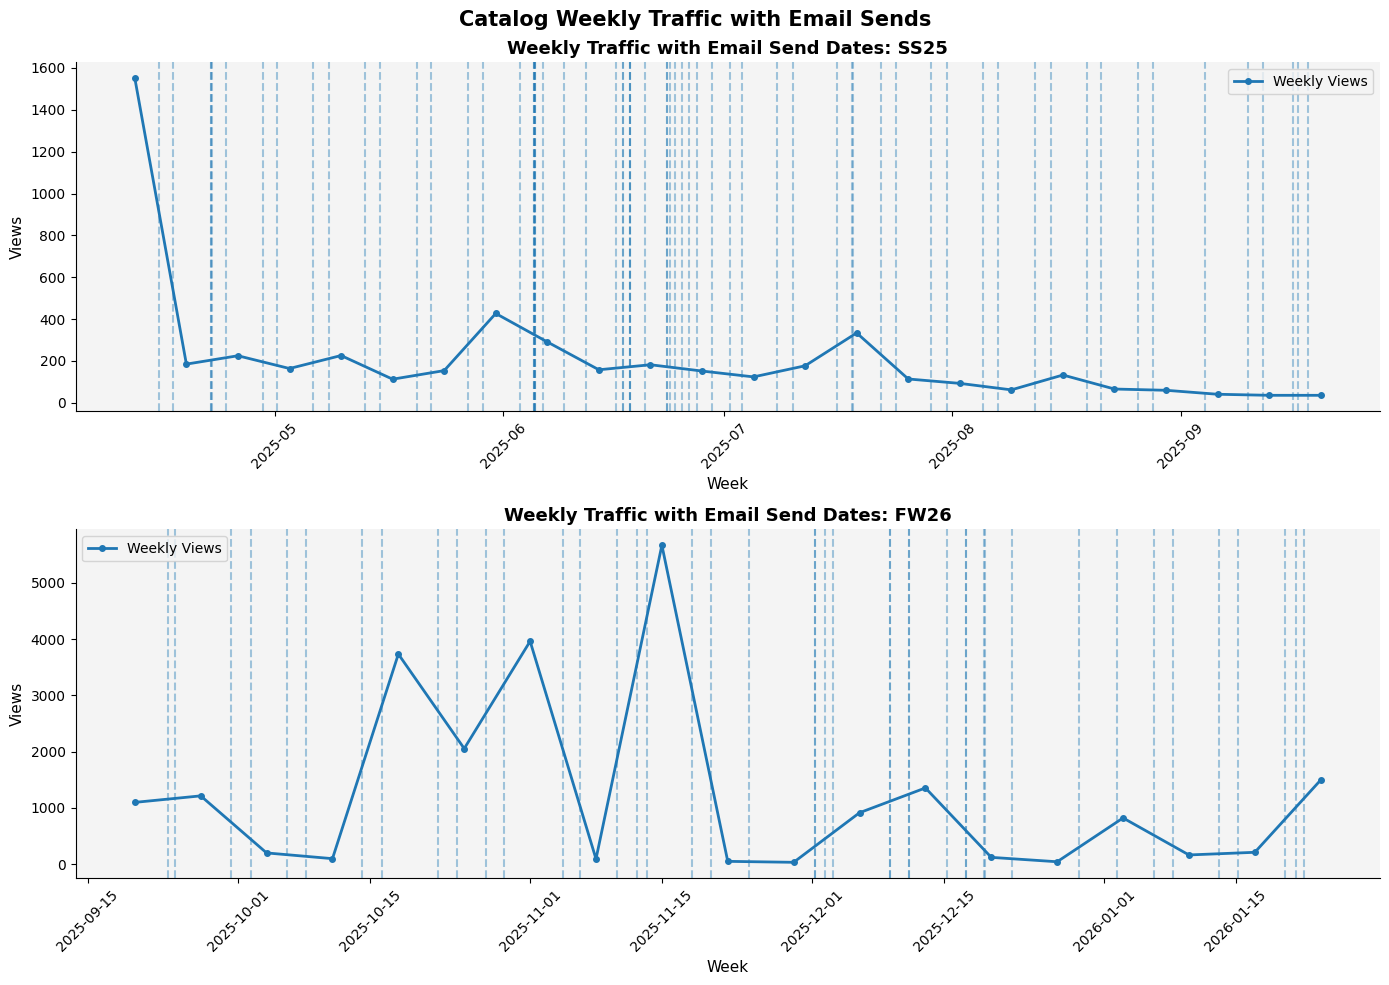

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=False)

# -----------------------
# SS25
# -----------------------
axes[0].plot(
    editions_ss25_google_wbw['end_date'],
    editions_ss25_google_wbw['views'],
    linewidth=2,
    marker='o',
    markersize=4,
    label='Weekly Views'
)

for _, row in filtered_emails_ss25.iterrows():
    axes[0].axvline(
        row['Sent'],
        linestyle='--',
        alpha=0.4
    )

axes[0].set_title('Weekly Traffic with Email Send Dates: SS25', fontweight='bold')
axes[0].set_xlabel('Week')
axes[0].set_ylabel('Views')
axes[0].tick_params(axis='x', rotation=45)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].legend()


# -----------------------
# FW26
# -----------------------
axes[1].plot(
    editions_fw26_google_wbw['end_date'],
    editions_fw26_google_wbw['views'],
    linewidth=2,
    marker='o',
    markersize=4,
    label='Weekly Views'
)

for _, row in filtered_emails_fw26.iterrows():
    axes[1].axvline(
        row['Sent'],
        linestyle='--',
        alpha=0.4
    )

axes[1].set_title('Weekly Traffic with Email Send Dates: FW26', fontweight='bold')
axes[1].set_xlabel('Week')
axes[1].set_ylabel('Views')
axes[1].tick_params(axis='x', rotation=45)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].legend()


fig.suptitle('Catalog Weekly Traffic with Email Sends', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [20]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Setup Subplots
fig = make_subplots(
    rows=2, cols=1, 
    shared_xaxes=False, 
    vertical_spacing=0.15,
    subplot_titles=("Weekly Traffic with Email Send Dates: SS25", "Weekly Traffic with Email Send Dates: FW26")
)

# ---------------------------------------------------------
# ROW 1: SS25
# ---------------------------------------------------------
fig.add_trace(
    go.Scatter(
        x=editions_ss25_google_wbw['end_date'],
        y=editions_ss25_google_wbw['views'],
        name='SS25 Views',
        mode='lines+markers',
        line=dict(color=ALA_BLUE, width=2),
        marker=dict(size=6),
        hovertemplate="<b>Date:</b> %{x|%b %d}<br><b>Views:</b> %{y}<extra></extra>"
    ),
    row=1, col=1
)

# Add Vertical Lines for SS25 Email Sends
for _, row in filtered_emails_ss25.iterrows():
    fig.add_vline(
        x=row['Sent'].timestamp() * 1000, # Plotly requires ms for timestamps in vlines
        line_width=1, line_dash="dash", line_color="gray", opacity=0.4,
        row=1, col=1
    )

# ---------------------------------------------------------
# ROW 2: FW26
# ---------------------------------------------------------
fig.add_trace(
    go.Scatter(
        x=editions_fw26_google_wbw['end_date'],
        y=editions_fw26_google_wbw['views'],
        name='FW26 Views',
        mode='lines+markers',
        line=dict(color=ALA_RED, width=2),
        marker=dict(size=6),
        hovertemplate="<b>Date:</b> %{x|%b %d}<br><b>Views:</b> %{y}<extra></extra>"
    ),
    row=2, col=1
)

# Add Vertical Lines for FW26 Email Sends
for _, row in filtered_emails_fw26.iterrows():
    fig.add_vline(
        x=row['Sent'].timestamp() * 1000,
        line_width=1, line_dash="dash", line_color="gray", opacity=0.4,
        row=2, col=1
    )

# 2. Update Layout & Styling
fig.update_layout(
    title_text="<b>Catalog Weekly Traffic with Email Sends</b>",
    title_x=0.5,
    height=800,
    width=1000,
    template="plotly_white",
    showlegend=False
)

# Update Axis Labels
fig.update_yaxes(title_text="Views", row=1, col=1)
fig.update_yaxes(title_text="Views", row=2, col=1)
fig.update_xaxes(title_text="Week", row=1, col=1)
fig.update_xaxes(title_text="Week", row=2, col=1)

fig.show()

<hr>

### 4.5 ALA Editions Weekly Traffic Over Time (SS25 & FW26)

In [21]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Setup Subplots with Secondary Y-Axes
fig = make_subplots(
    rows=2, cols=1, 
    shared_xaxes=False, 
    vertical_spacing=0.12,
    specs=[[{"secondary_y": True}], [{"secondary_y": True}]],
    subplot_titles=("SS25 Catalog — Weekly Views & Active Users", "FW26 Catalog — Weekly Views & Active Users")
)

# Configuration for the loops
catalogs = [
    {'df': ss25_home, 'color': ALA_BLUE, 'label': 'SS25', 'row': 1},
    {'df': fw26_home, 'color': ALA_RED, 'label': 'FW26', 'row': 2}
]

for cat in catalogs:
    df = cat['df']
    row = cat['row']
    
    # --- Primary Y-Axis: Views ---
    fig.add_trace(
        go.Scatter(
            x=df['week'],
            y=df['views'],
            name=f"{cat['label']} Views",
            mode='lines+markers',
            line=dict(color=cat['color'], width=3),
            marker=dict(size=6),
            fill='tozeroy',
            fillcolor=f"rgba{tuple(int(cat['color'].lstrip('#')[i:i+2], 16) for i in (0, 2, 4)) + (0.15,)}", # Dynamic HEX to RGBA 15%
            hovertemplate="<b>Week:</b> %{x}<br><b>Views:</b> %{y}<extra></extra>"
        ),
        row=row, col=1, secondary_y=False
    )
    
    # --- Secondary Y-Axis: Active Users ---
    fig.add_trace(
        go.Scatter(
            x=df['week'],
            y=df['active_users'],
            name=f"{cat['label']} Active Users",
            mode='lines+markers',
            line=dict(color=ACCENT, width=2, dash='dash'),
            marker=dict(size=5, symbol='square'),
            hovertemplate="<b>Week:</b> %{x}<br><b>Active Users:</b> %{y}<extra></extra>"
        ),
        row=row, col=1, secondary_y=True
    )

# 2. Update Layout & Styling
fig.update_layout(
    title_text="<b>ALA Editions Catalog — Weekly Traffic Comparison</b>",
    title_x=0.5,
    height=900,
    width=1000,
    template="plotly_white",
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="center", x=0.5)
)

# 3. Update Axis Titles
fig.update_xaxes(title_text="Week Number", row=1, col=1)
fig.update_xaxes(title_text="Week Number", row=2, col=1)

fig.update_yaxes(title_text="Views", title_font=dict(color=ALA_BLUE), row=1, col=1, secondary_y=False)
fig.update_yaxes(title_text="Active Users", title_font=dict(color=ACCENT), row=1, col=1, secondary_y=True)

fig.update_yaxes(title_text="Views", title_font=dict(color=ALA_RED), row=2, col=1, secondary_y=False)
fig.update_yaxes(title_text="Active Users", title_font=dict(color=ACCENT), row=2, col=1, secondary_y=True)

fig.show()

### 4.6 ALA Editions Top Sub-Pages by Total Views

In [22]:
import plotly.graph_objects as go

def top_subpages(df, catalog_path):
    # Filter for sub-pages (exclude the homepage)
    sub_pages = df[df['page_path_and_screen_class'] != catalog_path]
    # Group by page_path_and_screen_class, sum views, get top 10
    top = sub_pages.groupby('page_path_and_screen_class')['views'].sum().nlargest(10).reset_index()
    top.columns = ['page', 'views']
    return top

ALA_BLUE = '#1f4e79'
ALA_RED = '#c00000'

ss25_sub = top_subpages(editions_ss25_google, '/SS25catalog')
fw26_sub = top_subpages(editions_fw26_google, '/FW26catalog')

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=['SS25 — Top Sub-Pages by Views', 'FW26 — Top Sub-Pages by Views']
)

for col, (data, color, label) in enumerate(
    zip([ss25_sub, fw26_sub], [ALA_BLUE, ALA_RED], ['SS25', 'FW26']),
    start=1
):
    fig.add_trace(
        go.Bar(
            x=data['views'],
            y=data['page'],
            orientation='h',
            marker=dict(color=color, opacity=0.85),
            text=data['views'],
            textposition='outside',
            name=label
        ),
        row=1, col=col
    )

fig.update_layout(
    width=2000,
    title=dict(
        text='Most-Viewed Topic Categories in ALA Editions Catalogs',
        font=dict(size=24),
        x=0.5
    )
)

# Reverse y-axis on each subplot so largest bar is on top (matches matplotlib [::-1])
fig.update_yaxes(autorange='reversed', row=1, col=1)
fig.update_yaxes(autorange='reversed', row=1, col=2)

# Give each subplot its own x-axis range so text labels aren't clipped
for col in [1, 2]:
    fig.update_xaxes(automargin=True, row=1, col=col)

fig.show()

### 4.7 ALA Editions Average Engagement Time by Sub-Page (Engagement Quality)

Note: There was a [long URL](https://alastore.ala.org/FW26catalog/cataloging&ct=ga&cd=CAEYvgEqFDEzNTIzNDk30DkzNDAyNTc2NTgzMhpiMWUwNDQyYWRjOTFINmMz0mNvbTpIbjpVUw&usg=AOvVaw3PDM6LMzV0dRqwQdpcaDwk) that did not link to a currently functional page. This data point was omitted. This point was originally the top third point for FW26.

In [23]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def engagement_by_subpage(df, home_path, n=12):
    sub = df[df['page_path_and_screen_class'] != home_path].copy()
    sub['page'] = sub['page_path_and_screen_class'].str.split('/').str[-1]
    return (
        sub.groupby('page')
           .agg(avg_eng=('average_engagement_time_per_active_user', 'mean'),
                total_users=('active_users', 'sum'))
           .nlargest(n, 'avg_eng')
           .reset_index()
    )

ss25_eng = engagement_by_subpage(editions_ss25_google, '/SS25catalog')
fw26_eng = engagement_by_subpage(editions_fw26_google, '/FW26catalog')

# 1. Setup Subplots
fig = make_subplots(
    rows=1, cols=2, 
    subplot_titles=("SS25 — Avg Engagement by Sub-Page", "FW26 — Avg Engagement by Sub-Page"),
    horizontal_spacing=0.1
)

# Configuration for the loop
datasets = [
    {'df': ss25_eng, 'color': ALA_BLUE, 'label': 'SS25', 'col': 1},
    {'df': fw26_eng, 'color': ALA_RED, 'label': 'FW26', 'col': 2}
]

for item in datasets:
    df = item['df'].copy()
    # Reverse to match the "top-down" ranking
    df = df.iloc[::-1] 
    
    # --- REDUCED SIZING LOGIC ---
    max_users = df['total_users'].max()
    # Reduced multiplier (35) and base size (8) for smaller circles
    sizes = (df['total_users'] / max_users) * 30 + 8 

    fig.add_trace(
        go.Scatter(
            x=df['avg_eng'],
            y=df['page'],
            mode='markers',
            name=item['label'],
            marker=dict(
                size=sizes,
                color=item['color'],
                opacity=0.7,
                line=dict(width=1, color='white') # Slightly thicker border for definition
            ),
            hovertemplate=(
                "<b>Sub-Page:</b> %{y}<br>" +
                "<b>Avg Engagement:</b> %{x:.2f}s<br>" +
                "<b>Total Users:</b> %{customdata}<extra></extra>"
            ),
            customdata=df['total_users']
        ),
        row=1, col=item['col']
    )

# 2. Update Layout & Axes
fig.update_layout(
    title_text="<b>Engagement Quality by Content Category</b><br><sup>Bubble size represents relative user volume</sup>",
    title_x=0.5,
    height=600,
    width=1100,
    template="plotly_white",
    showlegend=False
)

fig.update_xaxes(title_text="Avg Engagement Time (seconds)")
fig.update_yaxes(title_text="Sub-Page", row=1, col=1)

fig.show()

### 4.8 ALA Editions Open, Click, & Unsubscribe Rates

In [24]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Define metrics and colors
metrics = [
    ('Opened %', 'Open Rate (%)', ALA_BLUE),
    ('Clicked %', 'Click-Through Rate (%)', ALA_RED),
    ('Unsubs %', 'Unsubscribe Rate (%)', ACRL_TEAL)
]

# 2. Create Subplots
fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=[f"<b>Distribution of {m[1]}</b>" for m in metrics],
    horizontal_spacing=0.08
)

for i, (col, label, color) in enumerate(metrics, 1):
    data_series = stats[col].dropna()
    mean_val = data_series.mean()
    
    # Add Histogram
    fig.add_trace(
        go.Histogram(
            x=data_series,
            nbinsx=30,
            marker_color=color,
            marker_line=dict(width=1, color='white'),
            opacity=0.8,
            showlegend=False, # We only want the Mean in the subplot legend
            hovertemplate=f"<b>{label} Range:</b> %{{x}}<br><b># of E-Blasts:</b> %{{y}}<extra></extra>"
        ),
        row=1, col=i
    )
    
    # Add Mean Line assigned to a specific legend anchor
    fig.add_trace(
        go.Scatter(
            x=[mean_val, mean_val],
            y=[0, 15], 
            mode='lines',
            name=f"Mean: {mean_val:.2f}%",
            line=dict(color='black', width=2, dash='dash'),
            legend=f"legend{i}", # Assigns to legend1, legend2, or legend3
            hoverinfo='skip'
        ),
        row=1, col=i
    )

# 3. Update Layout with 3 separate legend definitions
fig.update_layout(
    title_text="<b>ALA Editions E-Blast Engagement Distributions</b>",
    title_x=0.5,
    height=500,
    width=1200,
    template="plotly_white",
    
    # Legend for Plot 1 (Left)
    legend=dict(
        x=0.22, y=0.95, xanchor='right', yanchor='top',
        bgcolor='rgba(255,255,255,0.6)'
    ),
    # Legend for Plot 2 (Center)
    legend2=dict(
        x=0.58, y=0.95, xanchor='right', yanchor='top',
        bgcolor='rgba(255,255,255,0.6)'
    ),
    # Legend for Plot 3 (Right)
    legend3=dict(
        x=0.95, y=0.95, xanchor='right', yanchor='top',
        bgcolor='rgba(255,255,255,0.6)'
    ),
    margin=dict(t=100, b=80)
)

# 4. Label X-axes and Y-axis
fig.update_xaxes(title_text="Open Rate (%)", row=1, col=1)
fig.update_xaxes(title_text="Click-Through Rate (%)", row=1, col=2)
fig.update_xaxes(title_text="Unsubscribe Rate (%)", row=1, col=3)
fig.update_yaxes(title_text="# of E-Blasts", row=1, col=1)

fig.show()

### 4.9 Top & Bottom Opened eBlasts by Open Rate

In [25]:
top5    = stats.nlargest(5, 'Opened %')[['Date', 'Subject', 'Delivered', 'Opened %', 'Clicked %']]
display(top5.reset_index(drop=True))

,Date,Subject,Delivered,Opened %,Clicked %
0,7/24/25 6:03 AM,Technology and Well-Being at Your Library,43110,46.5,1.9
1,6/16/25 6:02 AM,Preview Books in the ALA Store at #ALAAC25!,8753,42.8,6.9
2,4/8/25 3:47 AM,"Spring/Summer '25 Catalog - Well-being, AI, fa...",6841,30.0,10.0
3,5/13/25 6:15 AM,Wellness and Stress Reduction Tips for Library...,129061,29.5,3.7
4,5/15/25 5:03 AM,"AASL Standards, Second Edition now available f...",43647,28.9,2.2


In [26]:
bottom5 = stats.nsmallest(5, 'Opened %')[['Date', 'Subject', 'Delivered', 'Opened %', 'Clicked %']]
display(bottom5.reset_index(drop=True))

,Date,Subject,Delivered,Opened %,Clicked %
0,4/8/25 3:24 AM,"Spring/Summer '25 ALA Editions catalog - AI, i...",1982,14.1,31.8
1,10/15/24 7:05 AM,Nuture a joy-positive library,66022,15.4,6.3
2,9/18/25 4:03 AM,"Fall/Winter '26 ALA Editions catalog - AI, lib...",202220,16.1,5.6
3,10/27/25 6:03 AM,OUT NOW: Essentials of STEM Librarianship,65147,16.2,4.6
4,10/2/24 9:30 AM,Free October 16th webinar - Programming and Co...,86611,17.0,5.4


### 4.10 Top Performers of ACRL Individual Book Promos (based on Open %)

In [27]:
top_acrl = acrl_indiv_emails.nlargest(10, 'Open %')[['Subject', 'Sent', '# Delivered', 'Open %', 'Click %']]
display(top_acrl.reset_index(drop=True))

,Subject,Sent,# Delivered,Open %,Click %
0,"New from ACRL - ""The Open Science Cookbook""",2025-06-11 11:14:00,18217,43.0,8.8
1,"New from ACRL - ""Supporting Neurodiverse Stude...",2025-06-24 11:14:00,18420,41.7,4.6
2,"New from ACRL - ""Legislative Advocacy and Publ...",2025-05-22 11:14:00,18295,39.0,13.4
3,"New from ACRL - ""Valuing the Community College...",2025-07-30 11:14:00,18314,38.1,3.2
4,"New from ACRL - ""Library Publishing: How to La...",2025-10-29 11:14:00,18350,33.4,4.0
5,"New from ACRL - ""Making Values-Based Decisions...",2025-09-16 11:14:00,18211,32.7,4.5
6,"New from ACRL - ""Navigating Disability in the ...",2025-10-09 11:14:00,18408,32.6,4.9
7,"New from ACRL - ""Training Library Instructors""...",2024-10-08 11:12:00,17664,29.8,6.1
8,"New from ACRL - ""From Interrogation to Integra...",2025-04-09 11:14:00,18153,29.1,4.5
9,"New from ACRL - ""Student Success Librarianship...",2025-03-11 11:14:00,17982,29.0,10.7


### 4\.11 Day of Week Analysis

In [28]:
# Add Day of Week ISO Code to ACRL and ALA Dataframes
acrl_all_emails['ISO Weekday'] = acrl_all_emails['Sent'].dt.dayofweek 

if not np.issubdtype(editions_ala_stats['Date'].dtype, np.datetime64):
    editions_ala_stats['Date'] = pd.to_datetime(editions_ala_stats['Date'])
editions_ala_stats['ISO Weekday'] = editions_ala_stats['Date'].dt.dayofweek

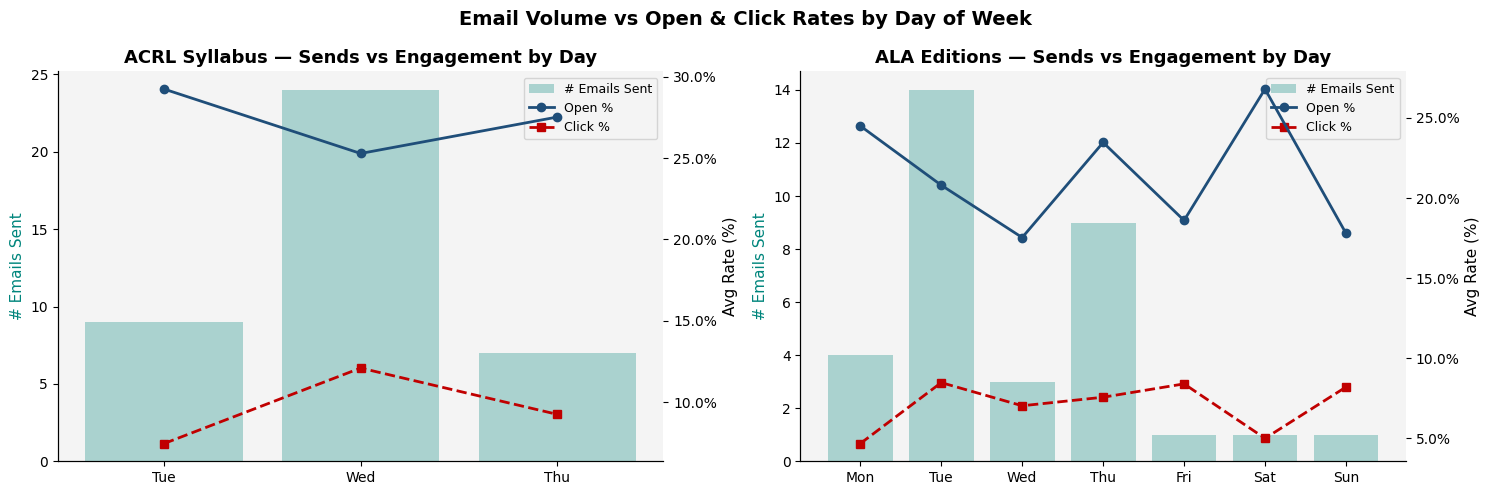

In [29]:
# Map ISO weekday → label
day_labels = {0:'Mon', 1:'Tue', 2:'Wed', 3:'Thu', 4:'Fri', 5:'Sat', 6:'Sun'}

acrl_day = acrl_all_emails.groupby('ISO Weekday').agg(
    emails_sent=('Name', 'count'),
    open_pct=('Open %', 'mean'),
    click_pct=('Click %', 'mean')
).reindex(day_labels.keys())

ala_day = editions_ala_stats.groupby('ISO Weekday').agg(
    emails_sent=('Subject', 'count'),
    open_pct=('Opened %', 'mean'),
    click_pct=('Clicked %', 'mean')
).reindex(day_labels.keys())

days = list(day_labels.values())

def dual_axis_plot(ax, day_data, title, bar_color, open_color, click_color):
    ax2 = ax.twinx()

    ax.bar(days, day_data['emails_sent'], color=bar_color, alpha=0.3, label='# Emails Sent')
    ax2.plot(days, day_data['open_pct'],  color=open_color,  marker='o', linewidth=2, label='Open %')
    ax2.plot(days, day_data['click_pct'], color=click_color, marker='s', linewidth=2, linestyle='--', label='Click %')

    ax.set_ylabel('# Emails Sent', color=bar_color)
    ax2.set_ylabel('Avg Rate (%)', color='black')
    ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
    ax.set_title(title, fontweight='bold')

    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, fontsize=9)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

dual_axis_plot(axes[0], acrl_day,  'ACRL Syllabus — Sends vs Engagement by Day',  ACRL_TEAL, ALA_BLUE, ALA_RED)
dual_axis_plot(axes[1], ala_day,   'ALA Editions — Sends vs Engagement by Day',   ACRL_TEAL,  ALA_BLUE,  ALA_RED)

plt.suptitle('Email Volume vs Open & Click Rates by Day of Week', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [30]:
# Map ISO weekday → label
day_labels = {0:'Mon', 1:'Tue', 2:'Wed', 3:'Thu', 4:'Fri', 5:'Sat', 6:'Sun'}

acrl_day = acrl_all_emails.groupby('ISO Weekday').agg(
    emails_sent=('Name', 'count'),
    open_pct=('Open %', 'mean'),
    click_pct=('Click %', 'mean')
).reindex(day_labels.keys())

ala_day = editions_ala_stats.groupby('ISO Weekday').agg(
    emails_sent=('Subject', 'count'),
    open_pct=('Opened %', 'mean'),
    click_pct=('Clicked %', 'mean')
).reindex(day_labels.keys())

days = list(day_labels.values())

def dual_axis_plotly(fig, day_data, title, bar_color, open_color, click_color, col):
    fig.add_trace(go.Bar(
        x=days, y=day_data['emails_sent'],
        name='# Emails Sent', marker_color=bar_color, opacity=0.3,
        showlegend=(col == 1)
    ), row=1, col=col)

    fig.add_trace(go.Scatter(
        x=days, y=day_data['open_pct'],
        name='Open %', mode='lines+markers',
        marker=dict(symbol='circle'), line=dict(color=open_color, width=2),
        showlegend=(col == 1)
    ), row=1, col=col)

    fig.add_trace(go.Scatter(
        x=days, y=day_data['click_pct'],
        name='Click %', mode='lines+markers',
        marker=dict(symbol='square'), line=dict(color=click_color, width=2, dash='dash'),
        showlegend=(col == 1)
    ), row=1, col=col)

    fig.update_yaxes(title_text='# Emails Sent', row=1, col=col)
    fig.update_xaxes(title_text='Day of Week', row=1, col=col)

fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'secondary_y': True}, {'secondary_y': True}]],
    subplot_titles=['ACRL Syllabus — Sends vs Engagement by Day',
                    'ALA Editions — Sends vs Engagement by Day'],
    horizontal_spacing=0.08
)

dual_axis_plotly(fig, acrl_day, 'ACRL', ACRL_TEAL, ALA_BLUE, ALA_RED, col=1)
dual_axis_plotly(fig, ala_day,  'ALA',  ACRL_TEAL, ALA_BLUE, ALA_RED, col=2)

fig.update_layout(
    title=dict(text='Email Volume vs Open & Click Rates by Day of Week', font=dict(size=14)),
    barmode='group',
    height=500, width=1300
)

fig.show()

<hr>

### 4.12 ALA Email Body Text Analysis

In [31]:
# Prepare the text data (email body text)
subjects = editions_ala_stats['Body Text'].fillna('')

# Initialize TF-IDF Vectorizer with English stop words, limiting to top 20 features
vectorizer = TfidfVectorizer(stop_words='english', max_features=20)

# Fit and transform the body text
tfidf_matrix = vectorizer.fit_transform(subjects)

# Get feature names and mean TF-IDF scores across all documents
feature_names = vectorizer.get_feature_names_out()
tfidf_scores = tfidf_matrix.mean(axis=0).A1

# Create a DataFrame for top words
top_words = pd.DataFrame({
    'word': feature_names,
    'score': tfidf_scores
}).sort_values('score', ascending=False)

# Display the top words
print("Top TF-IDF words in ALA email body text:")
display(top_words)

# Visualize with a horizontal bar chart (all bars same color, lengths based on TF-IDF score)
fig = go.Figure()
fig.add_trace(
    go.Bar(
        x=top_words['score'],
        y=top_words['word'],
        orientation='h',
        marker_color='#1f4e79',  # ALA Blue
        name='TF-IDF Score'
    )
)
fig.update_layout(
    title='Top TF-IDF Words in ALA Editions Email Body Text',
    xaxis_title='TF-IDF Score',
    yaxis_title='Word',
    yaxis={'categoryorder': 'total ascending'},  # Sort by score
    height=600,
    width=800
)
fig.show()

Top TF-IDF words in ALA email body text:


,word,score
11,library,0.111010
10,libraries,0.055272
16,school,0.054721
13,management,0.045832
2,ala,0.044434
14,new,0.041313
8,information,0.039783
4,book,0.036861
7,guide,0.035895
17,titles,0.035733


### 4.13 Body Length vs. Open Rate & Body Length vs. Click Rate

In [32]:
def add_trendline(fig, x, y, row, col, color="gray", dash="dash", width=1.2):
    # keep only valid numeric pairs
    x = pd.to_numeric(x, errors="coerce")
    y = pd.to_numeric(y, errors="coerce")
    mask = x.notna() & y.notna()
    x_clean = x[mask]
    y_clean = y[mask]

    if len(x_clean) < 2:
        return fig  # not enough points

    z = np.polyfit(x_clean, y_clean, 1)
    x_line = np.linspace(x_clean.min(), x_clean.max(), 100)
    y_line = np.poly1d(z)(x_line)

    fig.add_trace(
        go.Scatter(
            x=x_line,
            y=y_line,
            mode="lines",
            line=dict(color=color, dash=dash, width=width),
            showlegend=False
        ),
        row=row, col=col
    )
    return fig

In [33]:
# ALA Email Body Length vs Engagement
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

# Calculate body length (assuming 'Body Text' column exists)
editions_ala_stats['body_length'] = editions_ala_stats['Body Text'].str.len()

# Create subplots for Open Rate and Click Rate
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Body Length vs. Open Rate', 'Body Length vs. Click Rate'),
    horizontal_spacing=0.1
)

# Data for Open Rate
x_open = editions_ala_stats['body_length']
y_open = editions_ala_stats['Opened %']

# Add scatter for Open Rate
fig.add_trace(
    go.Scatter(
        x=x_open,
        y=y_open,
        mode='markers',
        marker=dict(
            size=12,
            color=ALA_BLUE,
            opacity=0.8,
            line=dict(width=1.5, color='white') # White outline
            ),
        name='Open Rate'
    ),
    row=1, col=1
)

# Open trendline (subplot 1)
add_trendline(
    fig,
    editions_ala_stats["body_length"],
    editions_ala_stats["Opened %"],
    row=1, col=1,
    color='dimgray', dash="dash", width=1
)

# Data for Click Rate
x_click = editions_ala_stats['body_length']
y_click = editions_ala_stats['Clicked %']

# Add scatter for Click Rate
fig.add_trace(
    go.Scatter(
        x=x_click,
        y=y_click,
        mode='markers',
        marker=dict(
            color=ALA_RED,
            size=12,
            opacity=0.8,
            line=dict(width=1.5, color='white') # White outline
            ),
        name='Click Rate'
    ),
    row=1, col=2
)

# Click trendline (subplot 2)
add_trendline(
    fig,
    editions_ala_stats["body_length"],
    editions_ala_stats["Clicked %"],
    row=1, col=2,
    color='dimgray', dash="dash", width=1
)

# Add trendline for Click Rate
if len(x_click) > 1:
    try:
        coeff_click = np.polyfit(x_click, y_click, 1)
        line_x_click = np.linspace(x_click.min(), x_click.max(), 100)
        line_y_click = coeff_click[0] * line_x_click + coeff_click[1]
        fig.add_trace(
            go.Scatter(
                x=line_x_click,
                y=line_y_click,
                mode='lines',
                line=dict(dash='dash', color=ALA_RED),
                showlegend=False
            ),
            row=1, col=2
        )
    except:
        pass

# Update layout
fig.update_layout(
    title_text='<b>ALA Email Body Length vs. Engagement</b>',
    title_x=0.5,
    height=500,
    width=1000,
    template='plotly_white',
    # paper_bgcolor=LIGHT_GRAY,
    plot_bgcolor= "#E5ECF6",
    showlegend=False
)

# Update axes
fig.update_xaxes(title_text='Body Length (characters)', row=1, col=1, gridcolor='white')
fig.update_xaxes(title_text='Body Length (characters)', row=1, col=2, gridcolor='white')
fig.update_yaxes(title_text='Rate (%)', row=1, col=1, gridcolor='white')
fig.update_yaxes(title_text='Rate (%)', row=1, col=2, gridcolor='white')

fig.show()

 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  5 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
